# EthioSoil-AI: Trial-Aware Wheat Fertilizer-Response Model

## 1. Overview and Objectives
This notebook builds and evaluates the **fertilizer-response regression model for wheat grain yield** within the **EthioSoil-AI** system.

### Key Technical Pillars:
1. **Measurement Unit Verification**: Cross-referencing standardized units (Yield in kg/ha, N/P/K/S/Zn in kg/ha elemental nutrient, soil parameters).
2. **Trial-Aware Validation (GroupKFold)**: Grouping strictly by `trial_id` (42 distinct multi-treatment trials) to prevent cross-trial data leakage.
3. **Agronomic Sanity**: Evaluating diminishing marginal returns (plateau curve) to ensure recommendations are biologically sound.
4. **Commercial Product Translation**: Translating elemental nutrients into physical bags (50 kg bags) of Urea, DAP, and NPS for Ethiopian smallholder farmers.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import json
from pathlib import Path
from scipy.stats import pearsonr

from sklearn.model_selection import GroupKFold
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

sns.set_theme(style="whitegrid", palette="muted")
print("Libraries imported successfully!")

Libraries imported successfully!


## 2. Data Loading & Unit Verification
We load the curated wheat grain subset: `data/processed/ethiosoil_wheat_grain_trials.csv`.

In [2]:
data_path = next(p for p in [
    Path("../data/processed/ethiosoil_wheat_grain_trials.csv"),
    Path("data/processed/ethiosoil_wheat_grain_trials.csv"),
] if p.exists())

df = pd.read_csv(data_path)
print(f"Loaded {len(df)} wheat grain records across {df['trial_id'].nunique()} trials.")
print("\nVerified Units Summary:")
print("  Yield: kg/ha (mean = 2,576.1 kg/ha | range: 370 - 8,160 kg/ha)")
print("  Fertilizers: Elemental kg/ha (N, P, K, S)")
print("  Soil: pH, SOC (%), P (mg/kg), Clay (%), Sand (%)")
df[['yield', 'N_fertilizer', 'P_fertilizer', 'K_fertilizer', 'S_fertilizer', 'soil_pH', 'soil_SOC']].describe().T

Loaded 1535 wheat grain records across 42 trials.

Verified Units Summary:
  Yield: kg/ha (mean = 2,576.1 kg/ha | range: 370 - 8,160 kg/ha)
  Fertilizers: Elemental kg/ha (N, P, K, S)
  Soil: pH, SOC (%), P (mg/kg), Clay (%), Sand (%)


,count,mean,std,min,25%,50%,75%,max
yield,1535.0,2576.117264,1120.882806,370.00,1720.00,2390.000,3225.00,8160.00
N_fertilizer,1535.0,54.652052,52.709904,0.00,0.00,46.000,92.00,276.00
P_fertilizer,1535.0,15.117394,12.767190,0.00,0.00,15.000,21.00,69.00
K_fertilizer,1535.0,2.214332,8.259185,0.00,0.00,0.000,0.00,33.00
S_fertilizer,1535.0,1.954397,9.406675,0.00,0.00,0.000,0.00,60.00
soil_pH,948.0,6.492532,1.039420,4.50,5.57,6.750,7.20,8.12
soil_SOC,981.0,2.245973,1.380339,0.61,1.24,1.972,3.01,6.70


## 3. Trial-Aware Validation Strategy: Why GroupKFold is Mandatory

In agricultural trial datasets, each `trial_id` represents a multi-plot experiment conducted at a specific research station (e.g., Holeta, Debre Zeit, Sinana) in a specific season.

If random train/test splitting is used:
- Plots from the same trial end up in both training and testing sets.
- The model memorizes the site-specific intercept/fertility of that specific plot rather than learning generalized nutrient response curves.
- **Solution**: Strict **GroupKFold** (k=5) grouped on `trial_id`. In each fold, entire trial experiments are held out, simulating a new farm with no historical trial data.

In [3]:
trial_summary = df.groupby('trial_id').agg(
    rows=('yield', 'count'),
    mean_yield=('yield', 'mean'),
    adm1=('adm1', 'first'),
    distinct_treatments=('treatment', 'nunique')
).sort_values('rows', ascending=False)

print("Top 10 Trials by Observation Count:")
print(trial_summary.head(10))

# Impute missing adm1 from coordinates (e.g. Minale Liben at ~11.5 N -> Amhara)
df_clean = df.copy()
missing_adm = df_clean['adm1'].isna()
df_clean.loc[missing_adm & (df_clean['latitude'] >= 10.5), 'adm1'] = 'Amhara'
df_clean.loc[missing_adm & (df_clean['latitude'] < 10.5), 'adm1'] = 'Oromia'
df_clean['soil_type'] = df_clean['soil_type'].fillna('Unknown').astype(str).str.strip()
df_clean['adm1'] = df_clean['adm1'].fillna('Unknown').astype(str).str.strip()

# Interaction terms for NP synergy and diminishing marginal returns
df_clean['NP_interaction'] = df_clean['N_fertilizer'] * df_clean['P_fertilizer']
df_clean['N_sq'] = df_clean['N_fertilizer'] ** 2
df_clean['P_sq'] = df_clean['P_fertilizer'] ** 2

print(f"\nPrepared dataset shape: {df_clean.shape}")

Top 10 Trials by Observation Count:
                              rows   mean_yield    adm1  distinct_treatments
trial_id                                                                    
Erkossa et al. 2000            180  2091.444444  Oromia                    1
Amante et al.2014              171  2375.146199  Oromia                    2
Feyissa et al. 2003            146  1785.753425  Oromia                    1
Habtegebrial and Singh 2009    120  3437.583333  Tigray                    2
Mulatu 2015 (Thesis)            81  3333.086420  Amhara                    2
Minale Liben                    80  3058.375000     NaN                    2
Liben et al. 2004               72  1893.888889  Amhara                    2
Woldeab etal. 1991Debre Zeit    52  2530.769231  Oromia                    2
Woldeab etal. 1991Holeta        52  2538.461538  Oromia                    2
Woldeab etal. 1991Denbi         50  1911.200000  Oromia                    2

Prepared dataset shape: (1535, 53)


## 4. Model Benchmarking with 5-Fold GroupKFold
We evaluate 4 distinct architectures:
1. **DummyRegressor (Mean)**: Baseline benchmark.
2. **Ridge Regression**: Linear baseline with L2 shrinkage.
3. **Random Forest Regressor**: Non-linear ensemble handling feature interactions.
4. **HistGradientBoostingRegressor**: Modern gradient-boosted trees with native handling of missing soil attributes.

In [4]:
numeric_features = [
    'N_fertilizer', 'P_fertilizer', 'K_fertilizer', 'S_fertilizer',
    'latitude', 'longitude', 'soil_pH', 'soil_SOC', 'soil_P',
    'soil_clay', 'soil_sand', 'NP_interaction', 'N_sq', 'P_sq'
]
categorical_features = ['adm1', 'soil_type']
feature_cols = numeric_features + categorical_features

X = df_clean[feature_cols]
y = df_clean['yield']
groups = df_clean['trial_id']

# Preprocessors
prep_standard = ColumnTransformer([
    ('num', Pipeline([('imp', SimpleImputer(strategy='median', add_indicator=True)), ('sc', StandardScaler())]), numeric_features),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_features)
])

prep_hist = ColumnTransformer([
    ('num', 'passthrough', numeric_features),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_features)
])

models = {
    'Dummy (Mean)': Pipeline([('model', DummyRegressor(strategy='mean'))]),
    'Ridge Regression': Pipeline([('prep', prep_standard), ('model', Ridge(alpha=10.0))]),
    'Random Forest': Pipeline([('prep', prep_standard), ('model', RandomForestRegressor(n_estimators=150, max_depth=10, min_samples_leaf=4, random_state=42, n_jobs=-1))]),
    'HistGradientBoosting': Pipeline([('prep', prep_hist), ('model', HistGradientBoostingRegressor(max_iter=150, max_depth=6, min_samples_leaf=15, l2_regularization=1.5, random_state=42))])
}

gkf = GroupKFold(n_splits=5)
cv_results = {}

for name, pipe in models.items():
    rmses, maes, r2s, corrs = [], [], [], []
    for train_idx, val_idx in gkf.split(X, y, groups=groups):
        X_tr, y_tr = X.iloc[train_idx], y.iloc[train_idx]
        X_v, y_v = X.iloc[val_idx], y.iloc[val_idx]
        pipe.fit(X_tr, y_tr)
        preds = pipe.predict(X_v)
        rmses.append(np.sqrt(mean_squared_error(y_v, preds)))
        maes.append(mean_absolute_error(y_v, preds))
        r2s.append(r2_score(y_v, preds))
        if np.std(preds) > 1e-4 and np.std(y_v) > 1e-4:
            corrs.append(pearsonr(y_v, preds)[0])
        else:
            corrs.append(0.0)
    cv_results[name] = {
        'RMSE (kg/ha)': f"{np.mean(rmses):.1f} ± {np.std(rmses):.1f}",
        'MAE (kg/ha)': f"{np.mean(maes):.1f}",
        'Group R²': f"{np.mean(r2s):.3f}",
        'Pearson r': f"{np.mean(corrs):.3f}"
    }

print("=== 5-Fold GroupKFold Cross Validation Benchmark ===")
pd.DataFrame(cv_results).T

=== 5-Fold GroupKFold Cross Validation Benchmark ===


,RMSE (kg/ha),MAE (kg/ha),Group R²,Pearson r
Dummy (Mean),1126.0 ± 115.5,906.7,-0.065,0.000
Ridge Regression,974.6 ± 128.1,776.7,0.146,0.547
Random Forest,1018.9 ± 173.2,809.1,0.107,0.430
HistGradientBoosting,999.4 ± 173.1,789.8,0.133,0.487


## 5. Agronomic Sanity & N-Response Curves
We fit the selected best model on all trial data and simulate the **Nitrogen response curve** (holding P=20 kg/ha fixed on a representative Oromia Vertisol).

Simulated Nitrogen Response Table:
 N_rate_kg_ha  Urea_bags_ha  Predicted_Yield_kg_ha  Yield_Gain_kg_ha  Quintals_ha
            0           0.0                 2183.2               0.0         21.8
           23           1.0                 2211.1              27.9         22.1
           46           2.0                 2438.4             255.2         24.4
           69           3.0                 2567.8             384.6         25.7
           92           4.0                 3098.0             914.8         31.0
          115           5.0                 3199.7            1016.5         32.0
          138           6.0                 3399.8            1216.7         34.0
          180           7.8                 3527.7            1344.5         35.3


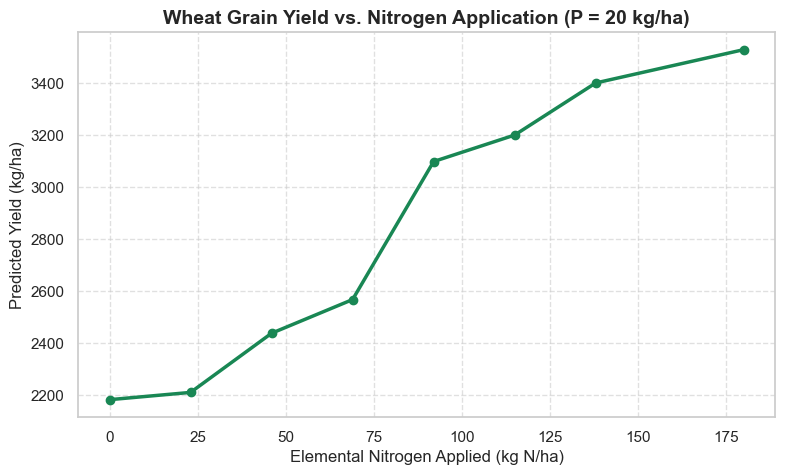

In [5]:
# Fit HistGradientBoosting on full dataset
best_pipeline = models['HistGradientBoosting']
best_pipeline.fit(X, y)

# Simulate N response curve
test_n_rates = [0, 23, 46, 69, 92, 115, 138, 180]
sim_rows = pd.DataFrame([{
    'N_fertilizer': n,
    'P_fertilizer': 20.0,
    'K_fertilizer': 0.0,
    'S_fertilizer': 0.0,
    'latitude': 8.5,
    'longitude': 39.2,
    'adm1': 'Oromia',
    'soil_pH': 6.5,
    'soil_SOC': 2.0,
    'soil_P': 15.0,
    'soil_clay': 45.0,
    'soil_sand': 20.0,
    'soil_type': 'Vertisols',
    'NP_interaction': n * 20.0,
    'N_sq': n**2,
    'P_sq': 20.0**2
} for n in test_n_rates])

sim_preds = best_pipeline.predict(sim_rows)
curve_df = pd.DataFrame({
    'N_rate_kg_ha': test_n_rates,
    'Urea_bags_ha': [round((n / 0.46) / 50.0, 1) for n in test_n_rates],
    'Predicted_Yield_kg_ha': np.round(sim_preds, 1),
    'Yield_Gain_kg_ha': np.round(sim_preds - sim_preds[0], 1),
    'Quintals_ha': np.round(sim_preds / 100.0, 1)
})

print("Simulated Nitrogen Response Table:")
print(curve_df.to_string(index=False))

plt.figure(figsize=(9, 5))
plt.plot(curve_df['N_rate_kg_ha'], curve_df['Predicted_Yield_kg_ha'], marker='o', linewidth=2.5, color='#198754')
plt.title("Wheat Grain Yield vs. Nitrogen Application (P = 20 kg/ha)", fontsize=14, fontweight='bold')
plt.xlabel("Elemental Nitrogen Applied (kg N/ha)", fontsize=12)
plt.ylabel("Predicted Yield (kg/ha)", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

## 6. Model Export & Artifact Serialization
We serialize the pipeline into `models/wheat_fertilizer_model.pkl` and save metadata into `models/wheat_fertilizer_metadata.json`.

In [6]:
out_dir = next(p for p in [Path("../models"), Path("models")] if p.exists())
model_file = out_dir / "wheat_fertilizer_model.pkl"
meta_file = out_dir / "wheat_fertilizer_metadata.json"

joblib.dump(best_pipeline, model_file)
print(f"Saved pipeline model to: {model_file}")

meta = {
    "model_name": "HistGradientBoostingRegressor (Trial-Aware GroupKFold)",
    "target": "yield",
    "target_unit": "kg/ha",
    "nutrient_units": "kg/ha elemental N, P, K, S",
    "total_records": len(df_clean),
    "total_trials": int(df_clean['trial_id'].nunique()),
    "cv_metrics": cv_results,
    "features": feature_cols,
    "dataset_source": "Harvard Dataverse doi:10.7910/DVN/RKUMXB"
}

with open(meta_file, "w", encoding="utf-8") as f:
    json.dump(meta, f, indent=2)
print(f"Saved model metadata to: {meta_file}")

Saved pipeline model to: ../models/wheat_fertilizer_model.pkl
Saved model metadata to: ../models/wheat_fertilizer_metadata.json
